# Data audit: KaraAgro AI Maize

**Purpose.** This notebook audits the labels before any training. It checks that the counts match the dataset page, measures the class imbalance and box sizes, looks at which classes share images, examines the shipped train/val/test split, filenames and image resolutions, and inspects the odd labels by eye.

**Status.** Complete. Every check has been run on the full export, and every question has a recorded decision.

**Data.** The Ultralytics ndjson export, `data/kara-agro-ai-maize.ndjson` (gitignored: it contains signed URLs, never commit it).

**How to read this notebook.** Sections 1 to 8 each open with what they check and end with a takeaway. Section 9 collects the findings, section 10 sets out the split we will build, section 11 records the decisions, and section 12 lists the limitations and next steps. Reusable logic lives in `src/audit.py` (loading) and `src/audit_checks.py` (checks); this notebook only calls and displays.

## 1. Setup and load

In [1]:
import sys
sys.path.append("..")          # lets the notebook import from src/
import pandas as pd
import matplotlib.pyplot as plt

from src.audit import load_ndjson
from src import audit_checks as ac

pd.set_option("display.max_columns", 50)
DATA_FILE = "../data/kara-agro-ai-maize.ndjson"
RESULTS = "../results"

In [2]:
names, images, boxes = load_ndjson(DATA_FILE)
print(len(images), "images,", len(boxes), "boxes,", boxes["cls"].nunique(), "classes")
images.head()

16543 images, 92932 boxes, 8 classes


,image,width,height,split,n_boxes
0,ds__1629436142698__dc6ff7b49e.jpg,3072,4096,test,0
1,ds__1629436540947__a90b020555.jpg,3072,4096,test,0
2,ds__1622342660033_jpg.rf.4fda699c70d3ec601fde7...,576,1024,test,0
3,ds__1629462590821__273f070b0e.jpg,3072,4096,test,0
4,ds__1622628387780__0c04dbecef.jpg,1080,1080,test,0


In [3]:
# Exact class names, so later cells can refer to them
EGG = ac.find_class(boxes, "egg")
LARVA = ac.find_class(boxes, "larva", exclude="damage")
FRASS = ac.find_class(boxes, "frass")
DAMAGE = ac.find_class(boxes, "damage")
EGG, LARVA, FRASS, DAMAGE

('fall armyworm egg',
 'fall armyworm larva',
 'fall armyworm frass',
 'fall armyworm larval damage')

## 2. Dataset overview and sanity checks

Do we have the images and boxes we expect (16,543 images and 92,932 boxes from the earlier load; the dataset page says 16,552 images)? Are there duplicates, empty images, broken boxes, or images missing a split? Does the per-class table match the dataset page?

In [4]:
ac.sanity_checks(images, boxes)

images                              16543
images (expected)                   16543
images (published)                  16552
boxes                               92932
boxes (expected)                    92932
duplicate image names                   0
images with no boxes                   99
boxes pointing at unknown images        0
images where n_boxes != box rows        0
boxes with zero or negative size        0
boxes with area_share > 1               0
missing split                           0
dtype: int64

In [5]:
# Our per-class counts next to the dataset page's table.
# Rows with NaN on one side mean the class names differ between sources.
ac.compare_to_published(boxes)

,images,boxes,images_pub,boxes_pub,images_diff,boxes_diff
fall armyworm larval damage,5135,38076,5138,38076,-3,0
healthy maize,4575,22707,4575,22707,0,0
fall armyworm frass,3372,15217,3376,15218,-4,-1
maize streak disease,6204,13607,6204,13607,0,0
fall armyworm larva,1451,1511,1454,1512,-3,-1
fall armyworm egg,301,1026,301,1026,0,0
none healthy,187,470,187,470,0,0
healthy images,32,318,32,318,0,0


### 2b. Test split and filename clues

The first cell confirms that the 99 images with no boxes are exactly the shipped test split. The second looks at the filenames. Names containing `.rf.` come from a Roboflow export and may be augmented copies of other images. The digits after `ds__` look like a capture timestamp in milliseconds, and some names carry a date such as `IMG_20220630`. We parse both into a date and use it as a rough proxy for a capture session. If many dates have images in both train and val, the shipped split was probably not grouped.

In [6]:
# Boxes per split: test should be 0
images.groupby("split")["n_boxes"].agg(["size", "sum"]).rename(columns={"size": "images", "sum": "boxes"})

,images,boxes
split,,
test,99,0
train,13159,73506
val,3285,19426


In [7]:
meta = ac.filename_metadata(images)
print(meta["roboflow"].sum(), "images have '.rf.' in the name")
display(pd.crosstab(meta["pattern"], meta["roboflow"], margins=True))
display(pd.crosstab(meta["roboflow"], meta["split"]))
ac.dates_across_splits(meta)

7273 images have '.rf.' in the name


roboflow,False,True,All
pattern,,,
date_in_name,2177,0,2177
epoch_ms,6134,5313,11447
other,959,1960,2919
All,9270,7273,16543


split,test,train,val
roboflow,,,
False,62,7440,1768
True,37,5719,1517


images with a parsed date       13624
distinct dates                     95
dates appearing in 2+ splits       90
images on those dates           13604
dtype: int64

**Takeaway (2b).** The shipped test split is confirmed empty (99 images, 0 boxes). 7,273 of 16,543 images (44%) have `.rf.` in the name, so they come from a Roboflow export and may be augmented copies. 5,313 of them have epoch-millisecond names and 1,960 have other (UUID-style) names. Dates parse for 13,624 images on 95 dates, and 90 of those dates have images in two or more splits (13,604 images). The shipped split was therefore not grouped by capture date, and related images almost certainly sit in both train and val.

### 2c. Groups of copies of one photo

An original photo and its Roboflow copies share a filename stem. The **strict** rule removes `ds__`, the extension, the trailing `__<hash>`, a Roboflow `_jpg.rf.<hash>` suffix and any inner `.jpg`. So `ds__1622342660033_jpg.rf.<hex>__<hash>.jpg` and `ds__1622342660033__<hash>.jpg` both become `1622342660033`, and a UUID name keeps its UUID together with any suffix after it.

The **loose** rule also counts these as the same photo: a trailing time-like suffix `-<h>_<m>_<s>` (as in `…CBF9850-5_29_36` or `IMG_…_095650-17_48_9`), a trailing copy number `-<n>` (as in `IMG_1286-2`), and `uuid_`-prefixed or lower-case UUIDs. These suffixes probably mark crops or re-exports of one original.

In [8]:
group_summary, group_sizes, stem_examples = ac.group_stats(images, rule="strict")
loose_summary, loose_sizes, _ = ac.group_stats(images, rule="loose")
with pd.option_context("display.max_colwidth", None):
    display(stem_examples)
display(pd.concat({"strict": group_sizes, "loose": loose_sizes}, axis=1).fillna(0).astype(int).T)  # images per group -> groups
pd.concat([group_summary, loose_summary], axis=1, keys=["strict", "loose"])

,pattern,roboflow,image,stem_strict,stem_loose
0,date_in_name,False,ds__IMG_20210507_095650-17_48_9__f02be70337.jpg,IMG_20210507_095650-17_48_9,IMG_20210507_095650
1,date_in_name,False,ds__IMG_20210529_091315-15_42_47__c87d1f319e.jpg,IMG_20210529_091315-15_42_47,IMG_20210529_091315
2,date_in_name,False,ds__IMG_20220707_084202_978__05333cc86c.jpg,IMG_20220707_084202_978,IMG_20220707_084202_978
3,epoch_ms,False,ds__1629436142698__dc6ff7b49e.jpg,1629436142698,1629436142698
4,epoch_ms,False,ds__1629436540947__a90b020555.jpg,1629436540947,1629436540947
5,epoch_ms,False,ds__1629462590821__273f070b0e.jpg,1629462590821,1629462590821
6,epoch_ms,True,ds__1622342660033_jpg.rf.4fda699c70d3ec601fde7919b4514ac3__765648c22b.jpg,1622342660033,1622342660033
7,epoch_ms,True,ds__1627715723248_jpg.rf.39ef1e040345246e65284060834fe85d__729b2383fa.jpg,1627715723248,1627715723248
8,epoch_ms,True,ds__1628678137950_jpg.rf.31f8b3fbd8458da57c5cdd54b1ff109c__83221cd35a.jpg,1628678137950,1628678137950
9,other,False,ds__uuid_d78e15ab-5312-41ab-9d27-56cb99434d62.jpg__b1621756d9.jpg,uuid_d78e15ab-5312-41ab-9d27-56cb99434d62,D78E15AB-5312-41AB-9D27-56CB99434D62


,1,2,3,4,5,6,7,9,10
strict,9524,3478,9,9,0,0,0,0,0
loose,9375,3066,43,105,36,22,21,2,1


,strict,loose
rule,strict,loose
images,16543,16543
groups,13020,12671
groups with 2+ images,3496,3296
images in such groups,7019,7168
largest group,4,10
groups spanning 2+ splits,1103,1104
images in groups spanning 2+ splits,2227,2597


**Takeaway (2c).** Under the strict rule the 16,543 images form 13,020 groups. 3,496 groups have two or more images, holding 7,019 images (42%), and 1,103 groups span two or more shipped splits, covering 2,227 images (13%). The loose rule gives 12,671 groups with a largest group of 10, and 1,104 groups span splits, covering 2,597 images. We use the loose rule for our split: a wrong merge only makes a group slightly larger, while a missed copy is leakage. This catches copies of the same file only, not different photos of the same plant or plot, so grouping by date stays as a sensitivity check.

Counts match the earlier load. No duplicates, bad boxes or missing splits. Against the dataset page the differences are 3 to 4 images for frass, larva and damage, and 0 for the rest. The 99 empty images are the test split.

## 3. Class imbalance (images and boxes)

How unequal are the classes when counted by images and by boxes, and how many boxes does a class have per image it appears in? A class that is common in boxes but rare in images (many boxes per image) behaves differently from one that is spread thinly.

In [9]:
summary = ac.class_summary(boxes)
summary

,images,boxes,image_share_%,box_share_%,boxes_per_image,box_ratio_to_largest
cls,,,,,,
fall armyworm larval damage,5135,38076,31.23,40.97,7.41,1.00
healthy maize,4575,22707,27.82,24.43,4.96,1.68
fall armyworm frass,3372,15217,20.51,16.37,4.51,2.50
maize streak disease,6204,13607,37.73,14.64,2.19,2.80
fall armyworm larva,1451,1511,8.82,1.63,1.04,25.20
fall armyworm egg,301,1026,1.83,1.10,3.41,37.11
none healthy,187,470,1.14,0.51,2.51,81.01
healthy images,32,318,0.19,0.34,9.94,119.74


In [10]:
# Distribution of boxes per image, within images that contain the class
ac.boxes_per_image_dist(boxes)

,p50,p90,p99,max
cls,,,,
fall armyworm egg,3.0,6.0,9.00,11
fall armyworm frass,4.0,9.0,16.00,30
fall armyworm larva,1.0,1.0,2.00,5
fall armyworm larval damage,5.0,16.0,35.00,52
healthy images,9.0,12.9,16.76,18
healthy maize,4.0,10.0,16.00,51
maize streak disease,1.0,5.0,9.00,14
none healthy,1.0,6.0,15.42,20


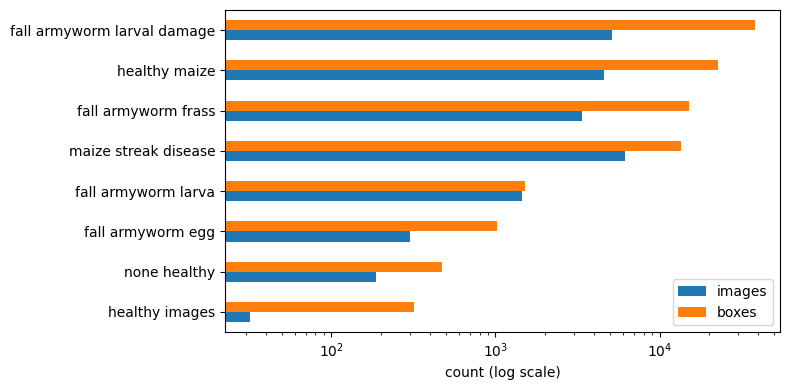

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
summary[["images", "boxes"]].sort_values("boxes").plot.barh(ax=ax, logx=True)
ax.set_xlabel("count (log scale)"); ax.set_ylabel("")
fig.tight_layout(); fig.savefig(f"{RESULTS}/class_counts.png", dpi=150)

Damage is the biggest class by boxes (38,076). Streak is biggest by images (6,204). Larva is 8.8% of images but only 1.6% of boxes, at about 1 per image. Eggs are 1.8% of images and 1.1% of boxes. The largest-to-smallest box ratio is 120:1 across all classes and 25 to 37:1 among the four FAW classes.

## 4. Box size per class

How large are the boxes, as a share of the image and as side length in pixels? This separates "rare" from "small", which the study needs to keep apart.

In [12]:
ac.box_size_by_class(boxes)

,area%_p10,area%_p50,area%_p90,side_px_p10,side_px_p50,side_px_p90
cls,,,,,,
fall armyworm larval damage,0.20,1.03,5.55,50.37,162.28,596.91
fall armyworm frass,0.20,1.26,7.49,54.84,192.54,651.00
fall armyworm larva,0.63,2.09,7.92,78.48,209.44,593.45
fall armyworm egg,0.51,2.86,11.91,129.15,483.92,1139.56
healthy images,1.83,8.90,24.61,123.21,258.23,433.21
healthy maize,3.11,11.34,43.63,170.44,561.27,1633.08
none healthy,3.81,21.34,95.17,151.49,357.93,2306.55
maize streak disease,4.95,23.59,96.96,302.07,827.69,2231.01


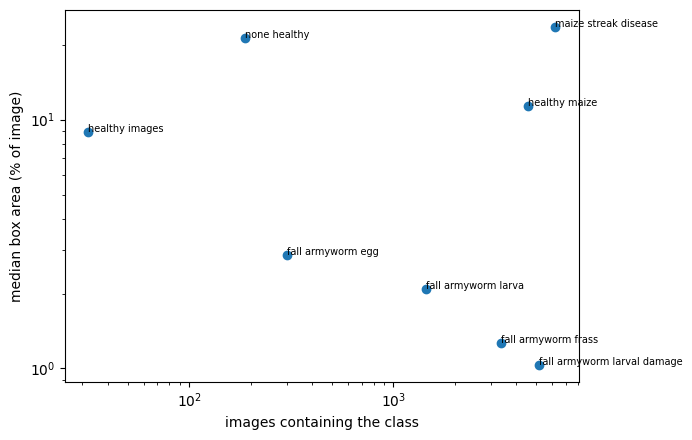

In [13]:
# Rarity versus size, one point per class
per = summary.join(ac.box_size_by_class(boxes)["area%_p50"])
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(per["images"], per["area%_p50"])
for c, r in per.iterrows():
    ax.annotate(c, (r["images"], r["area%_p50"]), fontsize=7)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("images containing the class"); ax.set_ylabel("median box area (% of image)")
fig.tight_layout(); fig.savefig(f"{RESULTS}/rarity_vs_size.png", dpi=150)

### 4b. Box size at the training input size

YOLO letterboxes every image so its long side equals `imgsz`. This cell rescales each box by its own image's factor, so it shows how many pixels a typical box has at 640 and at 1280. Section 11 (d) depends on these numbers.

In [14]:
pd.concat({imgsz: ac.box_side_at_imgsz(images, boxes, imgsz) for imgsz in [640, 1280]}, axis=1)

640                  1280               
                               p10    p50    p90    p10    p50     p90
cls                                                                   
fall armyworm larval damage   24.0   54.0  128.0   47.0  108.0   256.0
fall armyworm frass           24.0   60.0  149.0   47.0  120.0   297.0
fall armyworm larva           41.0   78.0  154.0   82.0  157.0   307.0
fall armyworm egg             39.0   93.0  191.0   79.0  186.0   382.0
healthy images                77.0  161.0  274.0  154.0  321.0   549.0
healthy maize                 95.0  184.0  367.0  190.0  368.0   735.0
none healthy                  90.0  206.0  607.0  180.0  412.0  1214.0
maize streak disease         123.0  269.0  538.0  247.0  539.0  1077.0

**Takeaway (4b).** At 640 px the median box side is 54 px for damage, 60 for frass, 78 for larva and 93 for eggs, and everything doubles at 1280. The smallest tenth of damage and frass boxes is about 24 px at 640, which is small but still detectable for YOLO. The earlier estimate of 25 to 76 px understated the sizes, as suspected.

Rare is not the same as small. Damage and frass are the smallest classes (median about 1% of the image). Eggs are rare but larger (2.9%).

## 5. Co-occurrence

Which classes appear in the same image? The diagonal is images per class. This tells us whether rare FAW classes come bundled with common ones, which matters for oversampling (oversampling an egg image also oversamples its damage boxes).

In [15]:
cooc = ac.cooccurrence(boxes)
cooc

cls,fall armyworm egg,fall armyworm frass,fall armyworm larva,fall armyworm larval damage,healthy images,healthy maize,maize streak disease,none healthy
cls,,,,,,,,
fall armyworm egg,301,59,31,277,0,0,0,0
fall armyworm frass,59,3372,1085,3175,0,20,0,0
fall armyworm larva,31,1085,1451,1190,0,0,2,0
fall armyworm larval damage,277,3175,1190,5135,0,4,26,0
healthy images,0,0,0,0,32,0,0,0
healthy maize,0,20,0,4,0,4575,16,0
maize streak disease,0,0,2,26,0,16,6204,0
none healthy,0,0,0,0,0,0,0,187


In [16]:
# Row-normalised: % of a row-class's images that also contain the column class
(100 * cooc.div(cooc.values.diagonal(), axis=0)).round(1)

cls,fall armyworm egg,fall armyworm frass,fall armyworm larva,fall armyworm larval damage,healthy images,healthy maize,maize streak disease,none healthy
cls,,,,,,,,
fall armyworm egg,100.0,19.6,10.3,92.0,0.0,0.0,0.0,0.0
fall armyworm frass,1.7,100.0,32.2,94.2,0.0,0.6,0.0,0.0
fall armyworm larva,2.1,74.8,100.0,82.0,0.0,0.0,0.1,0.0
fall armyworm larval damage,5.4,61.8,23.2,100.0,0.0,0.1,0.5,0.0
healthy images,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0
healthy maize,0.0,0.4,0.0,0.1,0.0,100.0,0.3,0.0
maize streak disease,0.0,0.0,0.0,0.4,0.0,0.3,100.0,0.0
none healthy,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0


Eggs only appear with FAW classes, and 92% of egg images also contain damage. Healthy and streak almost never overlap with FAW. Oversampling eggs will also oversample damage boxes.

## 6. Class counts per split

The export ships a `split` column. How many images and boxes of each class land in each split, and which classes are too thin to evaluate in val or test? Eggs are the main concern. Rows flagged below have fewer than `MIN_IMAGES` images in a split.

In [17]:
print(images["split"].value_counts(dropna=False))
per_split = ac.counts_per_split(images, boxes)
per_split

split
train    13159
val       3285
test        99
Name: count, dtype: int64


images        boxes      
split                        train   val  train   val
cls                                                  
fall armyworm egg              234    67    812   214
fall armyworm frass           2697   675  12243  2974
fall armyworm larva           1186   265   1230   281
fall armyworm larval damage   4080  1055  29908  8168
healthy images                  19    13    200   118
healthy maize                 3617   958  17829  4878
maize streak disease          5037  1167  10975  2632
none healthy                   147    40    309   161

In [18]:
MIN_IMAGES = 30
ac.flag_thin_splits(per_split, min_images=MIN_IMAGES)

images  boxes
cls            split               
healthy images train      19    200
               val        13    118

Test is unlabeled, so val is the only evaluation set. Eggs have 67 val images, which is enough for a rough estimate but gives wide error bars. "Healthy images" is thin in both train and val.

## 7. Image resolution heterogeneity

Images come at very different sizes (for example 3072x4096 and 576x1024). How many images are at each size, is the mix the same across splits, and does any class come mostly from one size? A class tied to one resolution can let the model learn the camera rather than the pest.

In [19]:
res = ac.resolution_counts(images)
print(len(res), "distinct resolutions")
res.head(15)

198 distinct resolutions


,images,share_%
size,,
3072x4096,3379,20.43
1536x2048,2244,13.56
810x1080,1412,8.54
2448x3264,884,5.34
2432x2432,868,5.25
780x1040,821,4.96
4096x3072,675,4.08
3024x4032,586,3.54
4032x2268,539,3.26


In [20]:
ac.resolution_by_split(images)

split,test,train,val,All
size,,,,
1536x2048,0,1820,424,2244
2432x2432,0,700,168,868
2448x3264,2,711,171,884
3024x4032,0,473,113,586
3072x4096,32,2759,588,3379
4032x2268,0,432,107,539
4096x3072,0,554,121,675
416x416,0,404,105,509
780x1040,26,639,156,821


In [21]:
# % of each class's images at each common resolution
ac.resolution_by_class(images, boxes)

size,1536x2048,2432x2432,2448x3264,3072x4096,780x1040,810x1080,other
cls,,,,,,,
fall armyworm egg,12.0,0.0,3.3,27.6,1.0,5.0,51.2
fall armyworm frass,8.2,2.5,7.4,17.3,5.3,9.5,50.0
fall armyworm larva,0.4,0.1,13.9,3.9,8.5,10.8,62.3
fall armyworm larval damage,7.0,3.1,5.2,25.2,3.9,9.8,45.9
healthy images,0.0,0.0,0.0,0.0,0.0,0.0,100.0
healthy maize,7.5,5.5,6.7,25.4,2.5,11.9,40.5
maize streak disease,24.8,5.8,4.6,14.3,7.0,4.6,38.9
none healthy,0.0,52.4,0.0,0.0,0.5,8.0,39.0


### 7b. Resolution shortcut test

Can image width and height alone tell whether an image contains any FAW class? A small decision tree is trained on width and height only and compared with always guessing the majority answer. If the tree beats the baseline by a lot, a detector could also use image size as a shortcut, so our split should balance resolutions across train, val and test.

This cell needs scikit-learn. If the import fails, run `%pip install scikit-learn` in a cell and restart the kernel.

**How to read the result.** Compare "tree accuracy" with "majority-baseline accuracy". A gain of a few points or less means image size says little about FAW, so no action is needed. A gain of about 10 points or more, well above the fold-to-fold spread, means size alone gives the answer away for many images. In that case our split should balance resolutions across train, val and test, and we should report per-resolution results for the FAW classes. Record the outcome in decision (e) in section 11.

In [22]:
FAW = [EGG, LARVA, FRASS, DAMAGE]
ac.resolution_shortcut_test(images, boxes, FAW)

images                         16444.000
share with the classes             0.335
majority-baseline accuracy         0.665
tree accuracy (5-fold mean)        0.681
tree accuracy (5-fold std)         0.005
gain over baseline                 0.017
dtype: float64

**Takeaway (7b).** Width and height alone barely predict FAW: the tree reaches 0.681 accuracy against a majority baseline of 0.665, a gain of 0.017 with a fold spread of 0.005. There is no meaningful image-size shortcut, so we do not need to balance resolutions across splits for this reason. Camera watermarks seen during inspection (section 8b) are a different possible cue and are not measured here.

Sizes vary widely, and some classes come mostly from one camera size (see above).

## 8. Label oddities

Two classes look like image-level tags rather than objects: **healthy images** (32 images, 318 boxes) and **none healthy** (187 images). Some boxes also sit in images where we would not expect them, such as frass boxes inside healthy-maize images. This section lists counts and example image names to open by hand.

In [23]:
HEALTHY_IMAGES = ac.find_class(boxes, "healthy images")
NONE_HEALTHY = ac.find_class(boxes, "none healthy")
HEALTHY_MAIZE = ac.find_class(boxes, "healthy maize")

pd.DataFrame({c: ac.class_overview(boxes, c) for c in [HEALTHY_IMAGES, NONE_HEALTHY]})

,healthy images,none healthy
images,32,187
boxes,318,470
images also containing other classes,0,0
other classes in those images,{},{}


In [24]:
# Do these classes' boxes cover the whole image (an image-level tag) or a region?
odd = boxes[boxes["cls"].isin([HEALTHY_IMAGES, NONE_HEALTHY])]
(odd["area_share"] * 100).groupby(odd["cls"]).describe().round(1)   # % of image

,count,mean,std,min,25%,50%,75%,max
cls,,,,,,,,
healthy images,318.0,11.4,9.3,0.0,4.3,8.9,16.5,59.2
none healthy,470.0,37.0,34.2,0.2,8.6,21.3,69.1,99.3


In [25]:
for c in [HEALTHY_IMAGES, NONE_HEALTHY]:
    print(c, ac.sample_images(boxes, c, n=10))

healthy images ['ds__1622645304846__d68da8b100.jpg', 'ds__1622624220654__99bc1c0241.jpg', 'ds__1622648305304__63c7ad7b51.jpg', 'ds__1622625862519__bf56233b00.jpg', 'ds__1622648345921__6704a1719e.jpg', 'ds__1622625703021__8bd76aadb2.jpg', 'ds__1622647483891__323ab8f6ef.jpg', 'ds__1622625766846__ac20237d41.jpg', 'ds__1622625713358__36737ef40c.jpg', 'ds__1622651106809__c466c5d9ef.jpg']
none healthy ['ds__1622656037321__04589fd4b1.jpg', 'ds__1625326248025__f8048f3dfb.jpg', 'ds__1622340912988__e5338dceae.jpg', 'ds__1622352085151__53342c7266.jpg', 'ds__1625325262902__42e83b3ae6.jpg', 'ds__1625325688742__85742f63ad.jpg', 'ds__1625325765954__9a5ed69c71.jpg', 'ds__1622341503576__8cb040e533.jpg', 'ds__1622340477504__6cf69e8e1a.jpg', 'ds__1625321125570__0871dd2639.jpg']


In [26]:
# Cross-class overlaps worth inspecting: FAW labels inside healthy-maize images
for guest in [FRASS, DAMAGE, LARVA, EGG]:
    display(ac.cross_class_examples(boxes, host=HEALTHY_MAIZE, guest=guest, n=10))

20 images contain both 'healthy maize' and 'fall armyworm frass' (36 'fall armyworm frass' boxes)


cls,fall armyworm frass,healthy maize
image,,
ds__1626703593107__941eb2639e.jpg,5,9
ds__1627906900198__afc121d4bc.jpg,3,5
ds__1626705677330__07d17a8c33.jpg,3,3
ds__1626704548911__e4cf031335.jpg,3,2
ds__1627906917742__fb092e8b30.jpg,2,4
ds__1627906935704__48d9beef13.jpg,2,3
ds__1626704410590__f0ae4a7e5c.jpg,2,7
ds__1626704743675__8cb18dae20.jpg,2,1
ds__1626704667710__ab94cd5910.jpg,2,2


4 images contain both 'healthy maize' and 'fall armyworm larval damage' (5 'fall armyworm larval damage' boxes)


cls,fall armyworm larval damage,healthy maize
image,,
ds__IMG-20210612-WA0166-13_13_15__b9ae333939.jpg,2,5
ds__IMG_20220630_101130_115__a4fd9798c3.jpg,1,1
ds__IMG_20220630_101337_488__9e58e90a4e.jpg,1,1
ds__IMG_20220630_102435_529__f2285ad1dc.jpg,1,1


0 images contain both 'healthy maize' and 'fall armyworm larva' (0 'fall armyworm larva' boxes)


cls,fall armyworm larva,healthy maize
image,,


0 images contain both 'healthy maize' and 'fall armyworm egg' (0 'fall armyworm egg' boxes)


cls,fall armyworm egg,healthy maize
image,,


### 8b. Visual inspection

The images were never downloaded, so these cells fetch each one through the signed URL in the ndjson. They shrink it to about 600 px, draw its boxes with one colour per class, and show the images in a grid. The URLs are never printed or saved. The annotated PNGs go to `data/inspection/`, which is gitignored, so they cannot be committed by accident. If the URLs have expired, the cell says so (usually HTTP 403); re-export the ndjson from Ultralytics and run again.

**What to look for.**
- **"Healthy images" and "none healthy".** Do the plants look clean and healthy, or diseased with a problem that is not FAW? Do the boxes mark regions such as leaves or plants, or do they cover the whole image like an image-level tag?
- **FAW boxes in healthy-maize images.** Does each frass or damage box sit on real frass or damage? If it does, the image is simply mixed; if not, it is a labelling error.

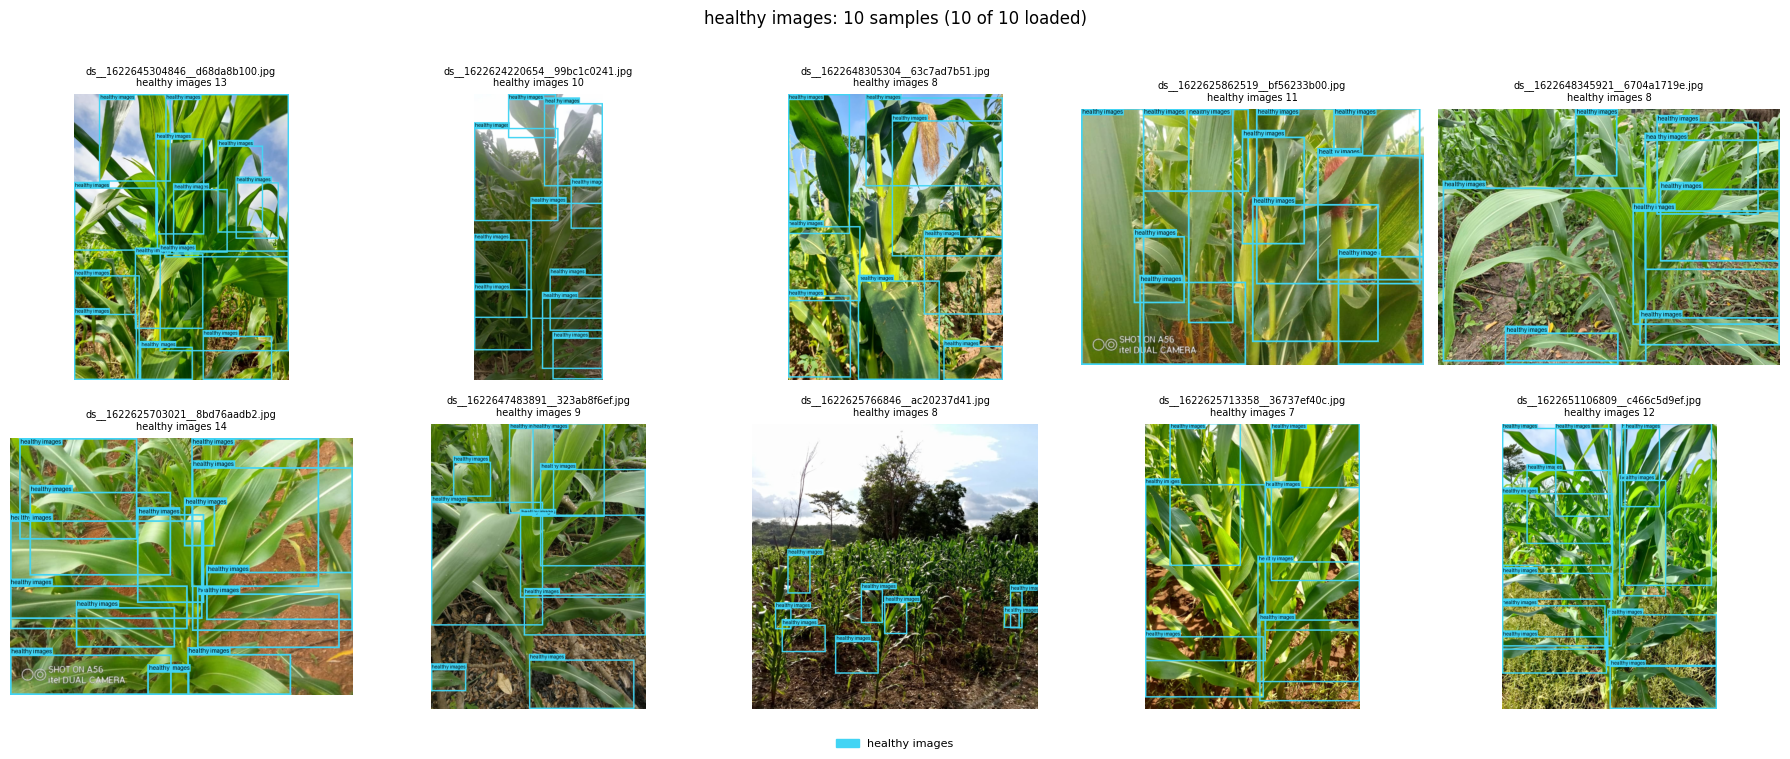

In [27]:
INSPECT_DIR = "../data/inspection"   # gitignored, like the ndjson

odd_samples = {c: ac.sample_images(boxes, c, n=10) for c in [HEALTHY_IMAGES, NONE_HEALTHY]}  # same seed (42) as section 8
fig = ac.contact_sheet(odd_samples[HEALTHY_IMAGES], DATA_FILE, "healthy images: 10 samples",
                       f"{INSPECT_DIR}/healthy_images")

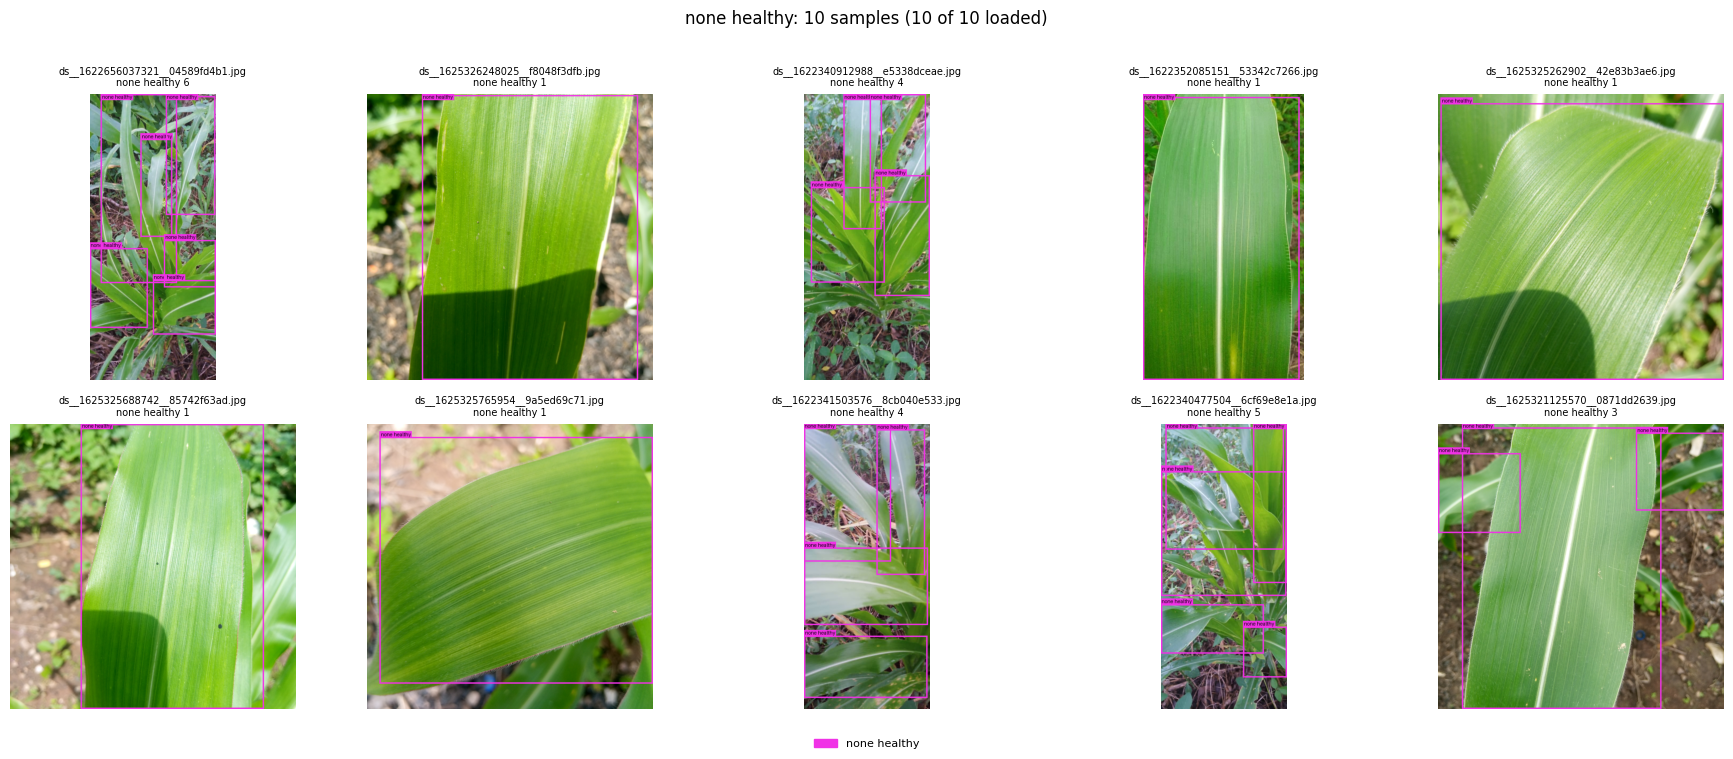

In [28]:
fig = ac.contact_sheet(odd_samples[NONE_HEALTHY], DATA_FILE, "none healthy: 10 samples",
                       f"{INSPECT_DIR}/none_healthy")

20 images contain both 'healthy maize' and 'fall armyworm frass' (36 'fall armyworm frass' boxes)
4 images contain both 'healthy maize' and 'fall armyworm larval damage' (5 'fall armyworm larval damage' boxes)


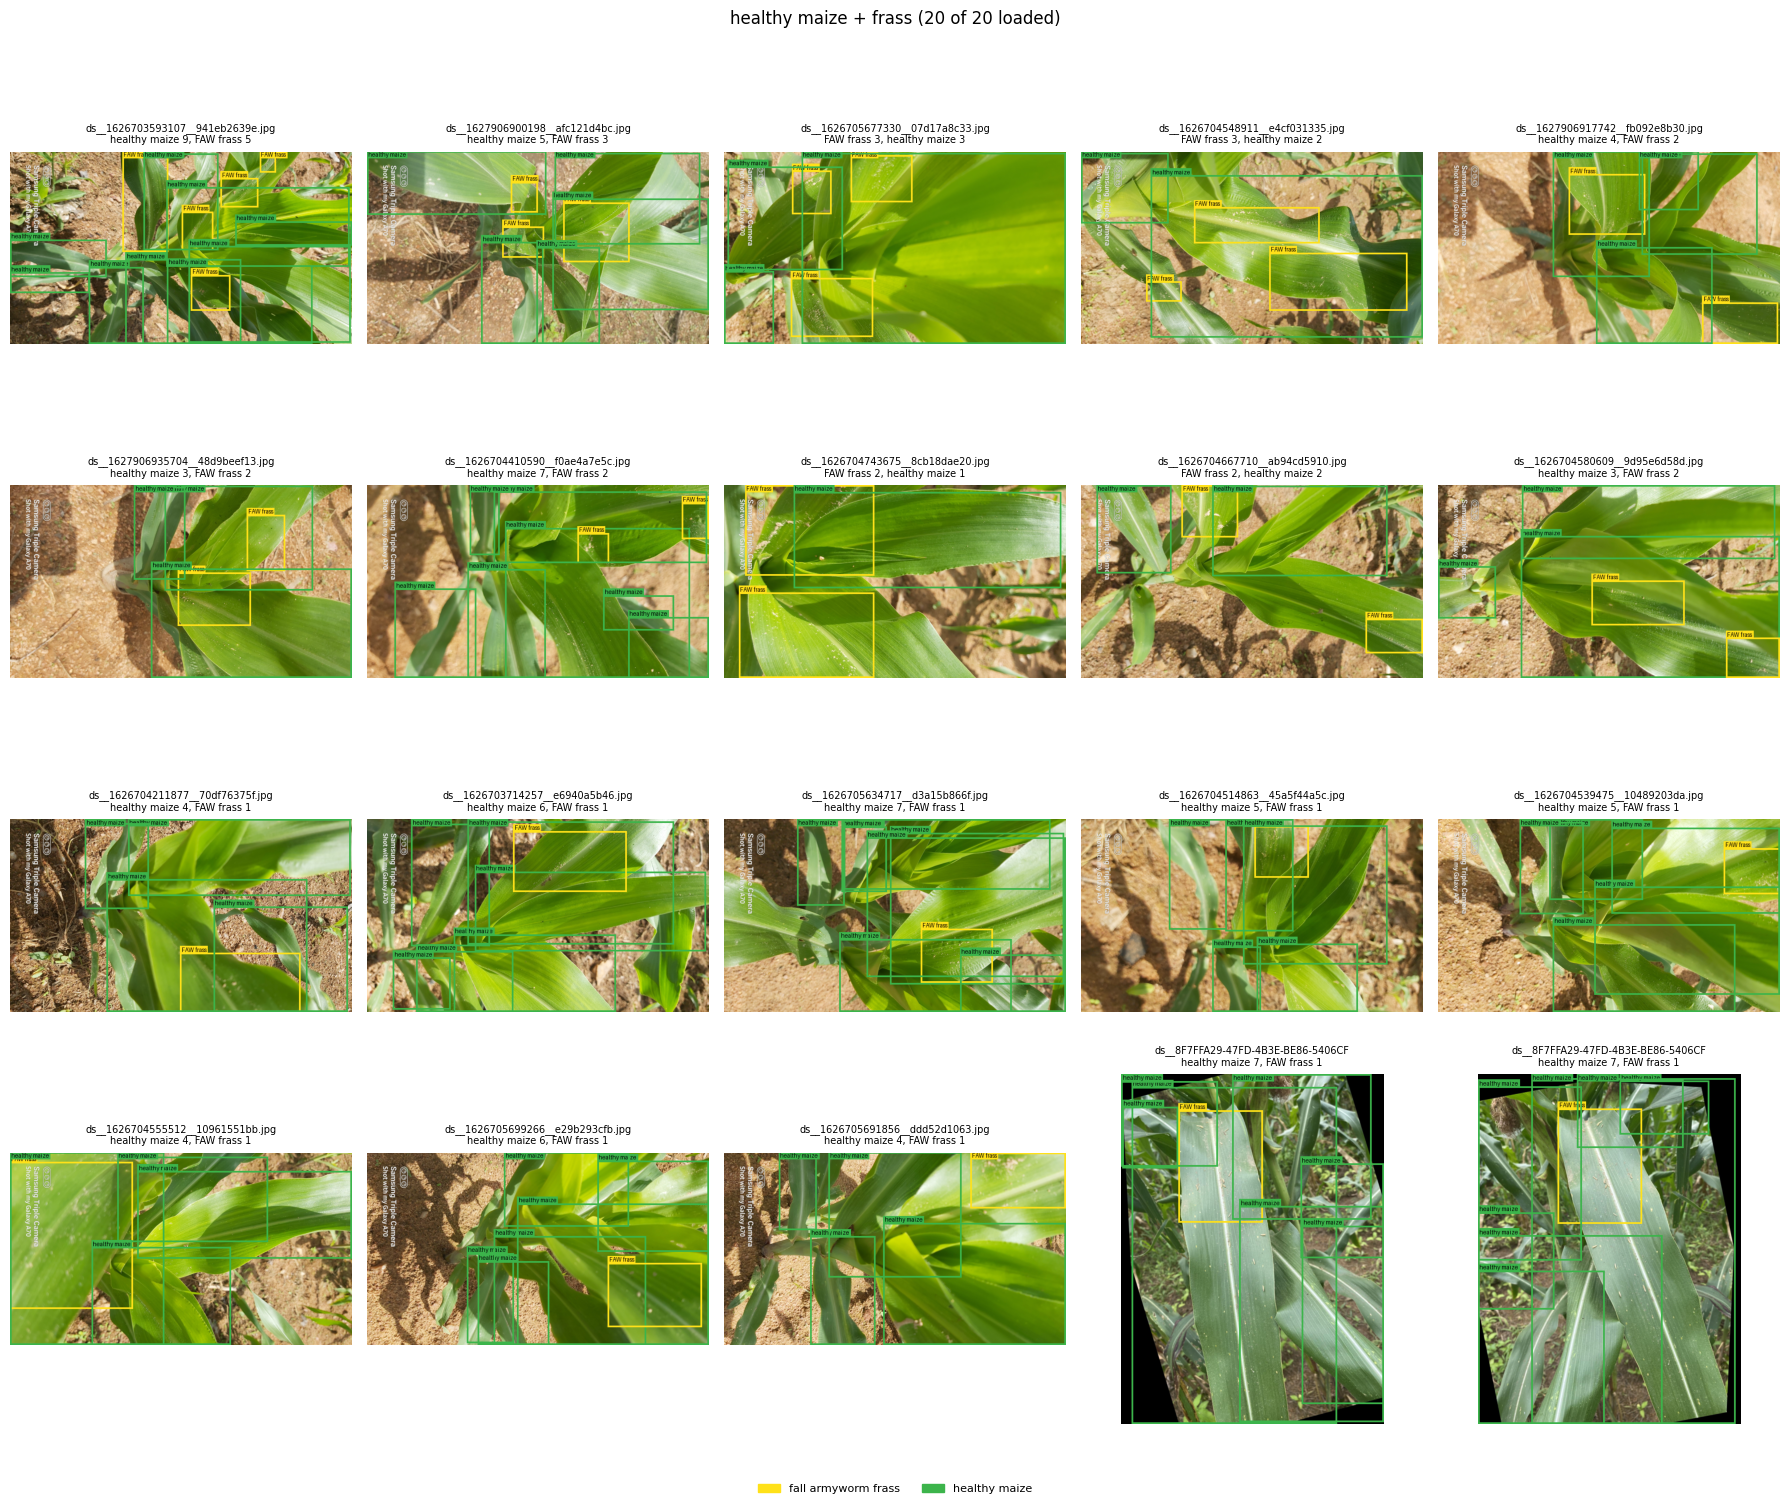

In [29]:
# All healthy-maize images that also contain frass (expected 20) or damage (expected 4)
overlap = {g: ac.cross_class_examples(boxes, host=HEALTHY_MAIZE, guest=g, n=100).index.tolist()
           for g in [FRASS, DAMAGE]}
fig = ac.contact_sheet(overlap[FRASS], DATA_FILE, "healthy maize + frass",
                       f"{INSPECT_DIR}/healthy_maize_frass", ncols=5)

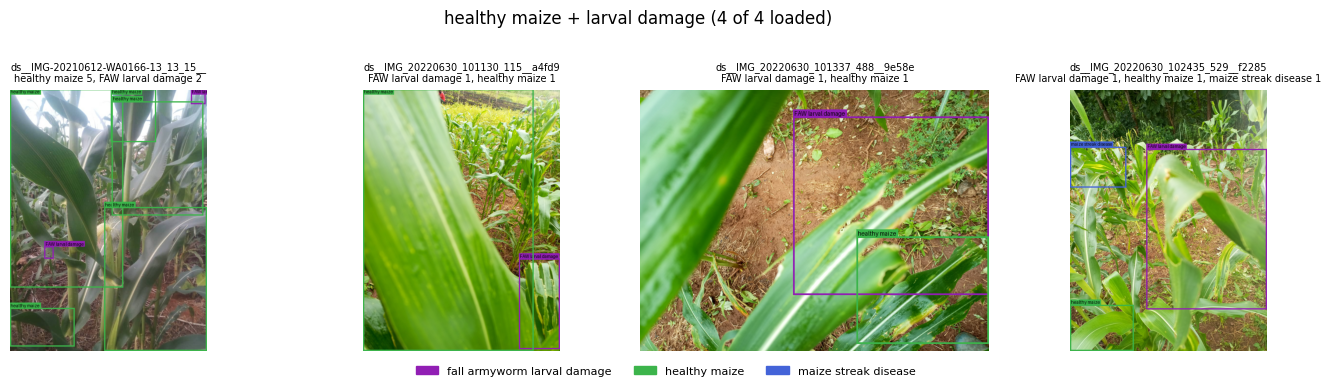

In [30]:
fig = ac.contact_sheet(overlap[DAMAGE], DATA_FILE, "healthy maize + larval damage",
                       f"{INSPECT_DIR}/healthy_maize_damage", ncols=4)

**Inspection notes.** Ten thumbnails per group were viewed; one "none healthy" image failed to load (RemoteDisconnected), so 9 were seen for that class. Hawa then checked a few "none healthy" images at full size and saw no FAW signs.

| Group | Images looked at | What the plants show | What the boxes cover | Verdict |
|---|---|---|---|---|
| healthy images | 10 | Healthy maize plants. All from one filename batch (`ds__16226…`). | Leaves, like healthy-maize boxes. | Healthy maize under another label name. Merge into healthy maize. |
| none healthy | 9 | Single-leaf close-ups, mostly 2432x2432, with no obvious disease. | Mixed, from small regions to the whole leaf. | Use as background negatives with boxes dropped. |
| healthy maize + frass | 20 | Real frass on plants that also carry healthy-maize boxes. | Frass boxes sit on frass; healthy-maize boxes are coarse regions that overlap everything. | Real co-occurrence. Keep. |
| healthy maize + damage | 4 | Real FAW damage. | Damage boxes sit on damage. | Real co-occurrence. Keep. |

**Other observations.** Two overlap images share a long UUID stem, and one has black rotated borders, so augmented near-duplicates are real (see section 2c). Many images carry camera watermark text, such as "Shot with my Galaxy A70" and "SHOT ON A56 itel DUAL CAMERA". That could act as a batch or shortcut cue; it is not measured.

**Takeaway (8b).** "Healthy images" is healthy maize under another name, and "none healthy" shows single-leaf close-ups with no FAW signs. The FAW boxes in healthy-maize images mark real frass and damage. Augmented near-duplicates are visible in the data, and camera watermarks are common.

Neither odd class overlaps with any other class. "Healthy images" has region-sized boxes (median 9%). "None healthy" ranges from small boxes to nearly the whole image (up to 99%). Frass boxes inside healthy-maize images affect only 20 images (36 boxes), and damage boxes only 4 images, so the effect on training is negligible. Section 8b checks them by eye.

## 9. Findings summary

**Data integrity**
- **The counts reproduce.** We have 16,543 images and 92,932 boxes, with no duplicate names and no broken boxes. The dataset page says 16,552 images, and its per-class counts differ from ours by 3 to 4 images for frass, larva and damage (frass is 4 fewer) and by 0 for the rest.

**Imbalance**
- **The imbalance is large.** The box ratio between the largest and smallest class is 120:1 across all classes, and 25 to 37:1 among the four FAW classes. Larva averages about 1 box per image, while damage averages 7.4.

**Size against rarity**
- **Rarity and size are separate problems.** Eggs are in only 301 images, but their median box covers 2.9% of the image. Frass and damage are the smallest boxes (median about 1% of the image) and among the most common.
- **The README's 16.7% egg size cannot be reproduced** from the raw labels, and its source is unknown.

**Co-occurrence**
- **Eggs only appear with FAW classes.** 92% of egg images also contain damage, so oversampling eggs also oversamples damage.

**Problems with the shipped split**
- **The test split has no labels** (99 images, 0 boxes), so val (3,285 images) is the only evaluation set in the shipped split. Eggs are split 234 train and 67 val.
- **Many images are augmented copies.** 7,273 images (44%) come from a Roboflow export (`.rf.` in the name).
- **The split leaks.** Of the 95 capture dates we can parse, 90 have images in two or more splits (13,604 images). Copies of the same file sit in different splits: 1,103 groups covering 2,227 images (13%) under the strict stem rule.

**Resolution and shortcuts**
- **Image sizes vary widely, and some classes are tied to sizes.** There are 198 distinct sizes. 52% of "none healthy" images are 2432x2432. 25% of streak images are 1536x2048, against 0.4% of larva images. 14% of larva images are 2448x3264, against 3% of egg images.
- **There is no image-size shortcut.** A tree on width and height only beats the majority baseline by 1.7 points (0.681 against 0.665).
- **Camera watermarks are common** (for example "Shot with my Galaxy A70"). They could be a batch cue; this was not measured.

**Odd classes and overlaps**
- **"Healthy images" (32 images) is healthy maize under another name**; all its images come from one filename batch.
- **"None healthy" (187 images) shows single-leaf close-ups with no FAW signs.** It never shares an image with another class, and its boxes range from small regions to the whole leaf.
- **FAW boxes in healthy-maize images are real.** 20 images hold 36 frass boxes and 4 images hold 5 damage boxes (about 0.2% of frass boxes), and they sit on real frass and damage.

**Box sizes at training resolution**
- **Boxes are a workable size at 640 px.** Median sides are 54 px for damage, 60 for frass, 78 for larva and 93 for eggs, and the smallest tenth of damage and frass is about 24 px. Everything doubles at 1280 px.

## 10. Our own split

**Why replace the shipped split.** The shipped test split is unlabelled, so it cannot be used for evaluation. 44% of images are Roboflow copies, 90 of the 95 capture dates appear in two or more splits, and 13% of images sit in copy groups that span splits (sections 2b and 2c). Eggs also need a guaranteed minimum in every evaluation split, which a random split does not promise.

**Method.**
- Pool the 16,444 labelled images, after merging "healthy images" into healthy maize. "None healthy" images join as background negatives with their boxes dropped.
- Group the images by the loose filename stem (`ac.group_stem(name, "loose")`, section 2c).
- Make a stratified grouped split on the presence of each of the six core classes, at about 70/15/15, with seed 42.
- Save the split as a CSV in `splits/` in the repo.
- As a sensitivity check, re-run the split grouped by capture date. Date alone gives only 95 groups of about 150 images, which is too coarse to be the main split.

**Assertions the split code must pass.**
- No group appears in two splits.
- Each split has at least about 40 egg images.
- The resolution mix is similar in each split.

**Egg numbers.** With 301 egg images, val and test each get about 45, so per-class results for eggs are reported with bootstrap confidence intervals.

Writing the split code is the next step and is not part of this audit.

## 11. Decisions

**(a) Own split.** We build our own grouped, stratified split, as set out in section 10.

**(b) "Healthy images" and "none healthy".** "Healthy images" (32 images) is merged into healthy maize. "None healthy" (187 images) is used as background negatives with its boxes dropped. Hawa checked samples and saw no FAW signs. The meaning of the label is undocumented (see section 12).

**(c) FAW boxes in healthy-maize images.** We keep them, because the inspection showed real frass and damage.

**(d) Image size.** All core runs use 640 px. 1280 px is used only on a subset of runs, and only if compute allows. Tiling or SAHI is an optional extension.

**(e) Image-size shortcut.** There is none (section 7b, gain 1.7 points over baseline), so no special balancing of resolutions is needed.

**(f) Class set.** We use six core classes: the four FAW classes plus healthy maize and maize streak. Together they give a graded imbalance from damage down to eggs. Whether to subsample negatives or common-class images to save compute is a design choice for the training plan, not an audit question.

## 12. Limitations and next steps

**Limitations**
- The visual inspection used about 10 thumbnails per group, plus a few "none healthy" images at full size. It is a spot check, not a full review.
- The meaning of the "none healthy" label is not documented anywhere. We treat its images as background because they show none of our six classes, not because we know what the label marks.
- Copy detection works from filenames, so it finds copies of the same file only. Different photos of the same plant or plot are not grouped, which is why the date-grouped split is kept as a sensitivity check.
- A few UUID names have a doubled extension (for example `…-5_29_36_jpeg`). Their stems keep the `_jpeg` ending, so the loose rule does not strip their time suffix. Copies of such a file still group together; only merges across different time suffixes are missed. The split code should strip that ending.
- Camera watermarks could be a batch cue for the model. We did not measure this.
- The README's 16.7% average egg size cannot be reproduced, and its source is unknown. The README table should be corrected.
- The dataset page reports 16,552 images; we load 16,543, and per-class counts differ by up to 4 images. The gap is small and unexplained.

**Next steps**
1. Write the split code from section 10 and check its assertions.
2. Do the imbalance literature pass and design the experiments.